# U-Net 학습: 일반 조건부 DDPM (AM 3클래스)

## 0. 실행 설정 / 라이브러리

In [2]:
import os
import subprocess
import sys
import time
from pathlib import Path

RUN_SEEDS = list(range(10))
DIFFUSION_EPOCHS = 500
DIFFUSION_LR = 2e-4
EMA_DECAY = 0.999
UNET_DIM = 32
GPU_ID = None
if GPU_ID is None:
    out = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=index,memory.used,utilization.gpu", "--format=csv,noheader,nounits"]).decode()
    rows = [tuple(int(v) for v in l.split(",")) for l in out.strip().splitlines()]
    GPU_ID = str(min(rows, key=lambda r: (r[1], r[2]))[0])
os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID
print("사용 GPU:", GPU_ID)

사용 GPU: 0


In [3]:
HERE = Path.cwd().resolve()
ROOT = HERE.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import torch
from tqdm.auto import tqdm

from models import Unet
from utils import set_seed, DEVICE, EMA
from diffusion import GaussianDiffusion
from data import load_am, build_imbalanced_group_split, CLASS_NAMES, TRAIN_COUNTS, TEST_COUNTS, NUM_CLASSES, IMAGE_SIZE

## 1. 데이터 / 설정

In [4]:
image_size, channels, num_classes = IMAGE_SIZE, 3, NUM_CLASSES
batch_size = 40
data_root = os.environ.get("DATA_ROOT", "../../data/AM_image_data_3split")
timesteps = 1000
CKPT_DIR = HERE / "checkpoints"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

all_x, all_y, all_groups = load_am(data_root)
print(f"클래스 {CLASS_NAMES} | 전체 이미지 {all_y.bincount().tolist()} | train {TRAIN_COUNTS}, test {TEST_COUNTS}")
ddpm = GaussianDiffusion(timesteps=timesteps, image_size=image_size, channels=channels)
train_x = train_y = None


def set_split(seed):
    global train_x, train_y
    tr, _ = build_imbalanced_group_split(all_y, all_groups, TRAIN_COUNTS, TEST_COUNTS, seed)
    train_x, train_y = all_x[tr].to(DEVICE), all_y[tr].to(DEVICE)
    assert train_y.bincount(minlength=num_classes).tolist() == TRAIN_COUNTS


def iterate_batches(n, bs):
    perm = torch.randperm(n, device=DEVICE)
    for i in range(0, n - bs + 1, bs):
        yield perm[i:i + bs]

클래스 ['Normal', 'Underfill_50FR', 'Underfill_Fan'] | 전체 이미지 [915, 591, 459] | train [800, 80, 80], test [100, 100, 100]


## 2. Diffusion 학습 (seed별)

In [ ]:
def ddpm_loss(model, x, y):
    t = torch.randint(0, timesteps, (x.size(0),), device=x.device)
    noise = torch.randn_like(x)
    return (model(ddpm.q_sample(x, t, noise), t, y) - noise).pow(2).mean()


def train_diffusion(seed):
    set_seed(seed)
    model = Unet(dim=UNET_DIM, channels=channels, num_classes=num_classes).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=DIFFUSION_LR)
    ema = EMA(model, decay=EMA_DECAY)
    losses, t0 = [], time.time()
    model.train()
    for epoch in range(DIFFUSION_EPOCHS):
        for idx in iterate_batches(len(train_x), batch_size):
            x = train_x[idx]
            loss = ddpm_loss(model, x, train_y[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            ema.update(model)
            losses.append(loss.item())
        if (epoch + 1) % max(1, DIFFUSION_EPOCHS // 10) == 0:
            print(f"[seed{seed}] epoch {epoch+1}/{DIFFUSION_EPOCHS} loss={np.mean(losses[-200:]):.4f} elapsed={time.time()-t0:.1f}s")
    return ema.model


for seed in RUN_SEEDS:
    set_split(seed)
    path = CKPT_DIR / f"ddpm_ema_seed{seed}.pt"
    if path.exists():
        print(f"[seed{seed}] 체크포인트 있음 → 건너뜀"); continue
    print(f"\n===== Diffusion 학습 | Seed {seed} | train {len(train_y)}장 {train_y.bincount().tolist()} =====")
    torch.save(train_diffusion(seed).state_dict(), path)
    print(f"[seed{seed}] 저장: {path}")

## 3. 샘플 확인

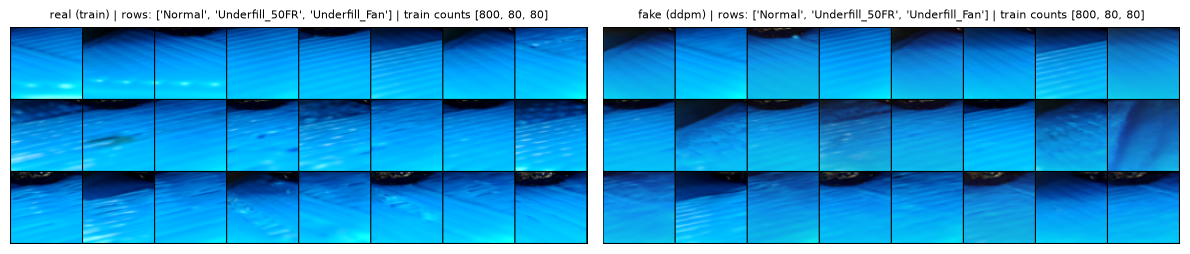

In [5]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

seed_show = RUN_SEEDS[0]
N_SHOW = 8
path = CKPT_DIR / f"ddpm_ema_seed{seed_show}.pt"
assert path.exists(), f"체크포인트가 없다: {path}"
set_split(seed_show)
m = Unet(dim=UNET_DIM, channels=channels, num_classes=num_classes).to(DEVICE)
m.load_state_dict(torch.load(path, map_location=DEVICE)); m.eval()
y = torch.tensor([c for c in range(num_classes) for _ in range(N_SHOW)], device=DEVICE)
set_seed(seed_show)
fake = ddpm.sample_ddpm_respaced(m, y, DEVICE, steps=50)
real = torch.cat([train_x[train_y == c][:N_SHOW] for c in range(num_classes)])

to_img = lambda x: make_grid(((x.detach().cpu() + 1) / 2).clamp(0, 1), nrow=N_SHOW, padding=1).permute(1, 2, 0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, x, name in zip(axes, (real, fake), ("real (train)", "fake (ddpm)")):
    ax.imshow(to_img(x)); ax.axis("off")
    ax.set_title(f"{name} | rows: {CLASS_NAMES} | train counts {TRAIN_COUNTS}", fontsize=8)
plt.tight_layout(); plt.show()

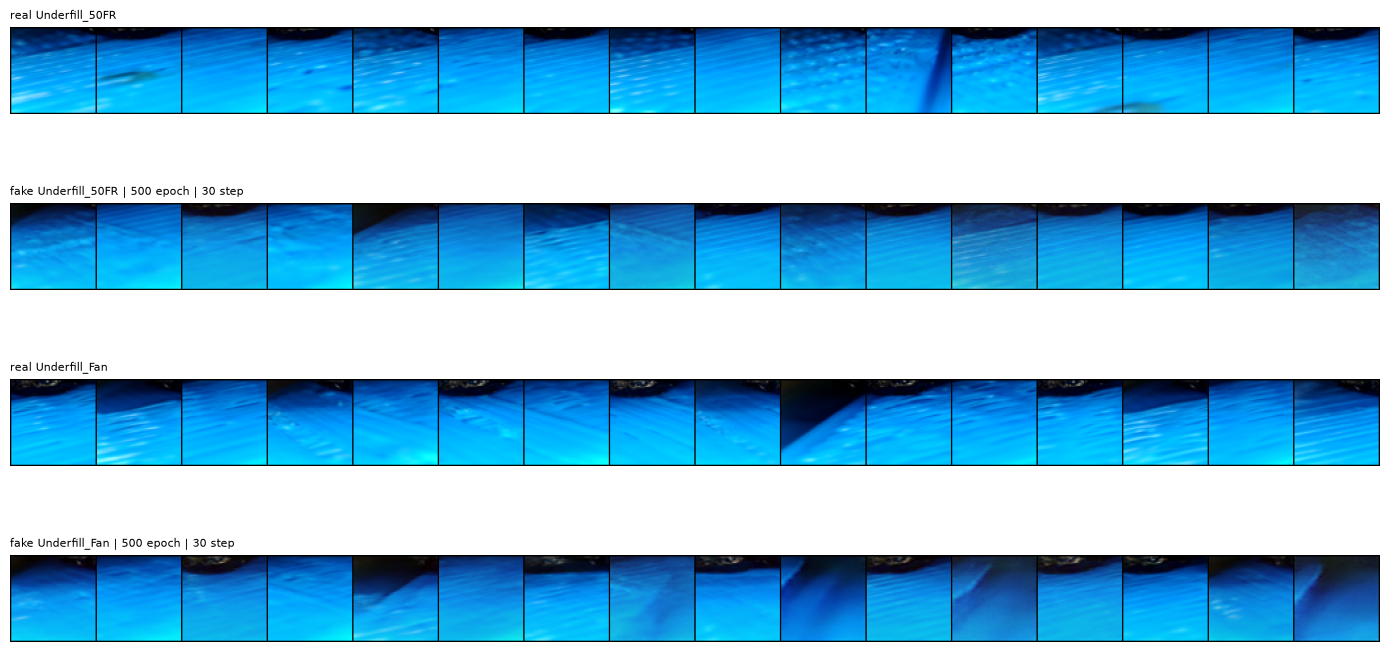

In [6]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

SEED_SHOW = 0
STEPS_LIST = [10]
N_SHOW = 16
OLD = HERE / "checkpoints" / f"ddpm_ema_seed{SEED_SHOW}.pt"

set_split(SEED_SHOW)
m = Unet(dim=UNET_DIM, channels=channels, num_classes=num_classes).to(DEVICE)
m.load_state_dict(torch.load(OLD, map_location=DEVICE)); m.eval()

to_img = lambda x: make_grid(((x.detach().cpu() + 1) / 2).clamp(0, 1), nrow=N_SHOW, padding=1).permute(1, 2, 0)
rows = []
for c in (1, 2):
    rows.append((f"real {CLASS_NAMES[c]}", train_x[train_y == c][:N_SHOW]))
    y = torch.full((N_SHOW,), c, dtype=torch.long, device=DEVICE)
    for s in STEPS_LIST:
        set_seed(SEED_SHOW)
        rows.append((f"fake {CLASS_NAMES[c]} | 500 epoch | {s} step", ddpm.sample_ddpm_respaced(m, y, DEVICE, steps=s)))
fig, axes = plt.subplots(len(rows), 1, figsize=(14, 1.9 * len(rows)))
for ax, (name, x) in zip(axes, rows):
    ax.imshow(to_img(x)); ax.axis("off"); ax.set_title(name, fontsize=8, loc="left")
plt.tight_layout(); plt.show()